# ♕ Female Chess Players: Titles, Federations and Online Play

An exploratory data analysis of **~4.8 million monthly FIDE rating records (2015–2024)** for
**66,556 female chess players**, combined with **~300,000 chess.com games**.

The analysis is organised in three parts:

1. **Titles and rating growth** – when do women earn master titles, and do younger title holders improve faster?
2. **Federations** – where are female players registered, which federations are growing, and which ones attract players from elsewhere?
3. **Online play** – linking chess.com accounts to FIDE profiles to compare online activity and performance with over-the-board ratings.

Each section follows the same structure: **question → approach (as a sequence of relational operations) → code → findings**.
Three hypotheses are tested formally with `scipy.stats`.


## Setup


In [1]:
# Uncomment if libraries are not installed in your environment
# %pip install --quiet pandas numpy matplotlib scipy

# Core packages
import pandas as pd
import numpy as np

# Visualization package (plotting only)
import matplotlib.pyplot as plt

# Statistical testing 
from scipy import stats

# Display options for pandas tabular outputs
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)

# Random seed for reproducibility
np.random.seed(123456789)

## Data

> The raw data files are **not included** in this repository. Place them in a `data/` folder to re-run the notebook (see README).

**FIDE rating lists** (`data/fide_ratings.csv.gz`) – monthly records from February 2015 to November 2024,
~4.8 million rows, one row per *player–month*. `(ID, DATE)` uniquely identifies each observation.

| Column | Description |
|--------|------------|
| ID | Unique FIDE player identifier |
| NAME | Player name |
| SEX | Player sex (`F` = female, `M` = male) |
| BORN | Year of birth |
| FED | Federation code (3-letter abbreviation) |
| FLAG | Activity status (`W` = active, `WI` = inactive) |
| DATE | Rating list month |
| TITLE | FIDE title (if any) |
| SRTNG / RRTNG / BRTNG | Standard / Rapid / Blitz rating |
| SGM / RGM / BGM | Number of Standard / Rapid / Blitz games in that period |

**chess.com games** (`data/chesscom_games.csv.gz`) and a **username → FIDE ID mapping** (`data/chesscom_fide_mapping.csv`) are used in Part 3.


In [2]:
def load_fide(path: str = "../data/fide_ratings.csv.gz") -> pd.DataFrame:
    """
    Loads the FIDE rating lists and returns it as a pandas DataFrame.
    """
    df = pd.read_csv(
        path, 
        parse_dates=["DATE"], 
        low_memory=False,
        dtype={
            "ID": "Int64",
            "NAME": "string",
            "SEX": "category",
            "BORN": "Int64",
            "FED": "category",
            "FLAG": "category",
            "TITLE": "category",
        })

    # Basic integrity checks

    assert df.duplicated(subset=["ID", "DATE"]).sum() == 0, \
        "(ID, DATE) is not unique."
    
    assert df["DATE"].notna().all(), \
        "DATE contains missing values."

    return df

# Load dataset
fide = load_fide()

In [3]:
fide.head(15)


,ID,NAME,SEX,BORN,FED,FLAG,DATE,TITLE,SRTNG,RRTNG,BRTNG,SGM,RGM,BGM
0,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-02-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
1,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-03-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
2,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-04-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
3,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-05-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
4,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-06-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
5,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-07-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
6,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-08-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
7,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-09-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
8,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-10-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
9,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-11-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN


In [4]:

fide.columns


Index(['ID', 'NAME', 'SEX', 'BORN', 'FED', 'FLAG', 'DATE', 'TITLE', 'SRTNG', 'RRTNG', 'BRTNG', 'SGM', 'RGM', 'BGM'], dtype='str')

## ♘ Part 1 — Titles and rating growth


### 1. Female player population

Isolate female players and validate the filter.


#### Approach

1. **Project** the SEX column from the full FIDE dataset and extract 
   distinct values — this produces a small relation R1 confirming 
   the domain of SEX (expected values: 'F', 'M').

2. **Select** rows where SEX = 'F' from the full FIDE dataset — 
   this produces relation R2 containing only female 
   player–month observations.

3. **Project** the SEX column from R2 and extract distinct values — 
   this produces relation R3 used to verify that no non-female 
   rows remain after filtering.

4. **Assert** that all rows in R2 have SEX = 'F' — this validates 
   the correctness of the filter operation.

5. **Aggregate** R2 by counting distinct ID values — this produces 
   the total number of unique female players in the dataset.


In [5]:
female_df = fide[fide["SEX"] == "F"]
female_df.head(10)

,ID,NAME,SEX,BORN,FED,FLAG,DATE,TITLE,SRTNG,RRTNG,BRTNG,SGM,RGM,BGM
0,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-02-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
1,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-03-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
2,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-04-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
3,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-05-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
4,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-06-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
5,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-07-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
6,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-08-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
7,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-09-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
8,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-10-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN
9,100145,"Felice, Carolina",F,<NA>,ARG,WI,2015-11-01,NaN,1879.0,NaN,NaN,0.0,NaN,NaN


In [6]:
print(f"Female player-month rows: {len(female_df):,}")
print(f"Unique female players:    {female_df['ID'].nunique():,}")


Female player-month rows: 4,786,232
Unique female players:    66,556


#### Findings

The dataset was filtered to keep only female players (SEX = 'F').
The output shows that the filtering worked correctly, as all rows
in the result have SEX = 'F'. The filtered dataset contains
4,786,232 rows in total, belonging to 66,556 unique female players
recorded between February 2015 and November 2024. Each player
appears multiple times because the data has one row per player
per month. For example, the first player in the table, Felice,
Carolina, appears once for each month she was active. This
filtered dataset is used as the starting point for all
the queries that follow.


### 2. Age at first master title

For each female player, infer the date she first appears with a Master or Grandmaster title and compute her age at that point.


#### Inferring title events

We are trying to infer an event &mdash; the first observed transition into a Master or Grandmaster title &mdash; from monthly rating records. We do **not** observe the true award date directly; we only observe whether a title is present in a given record.

If a player's **first appearance** in the dataset already includes a Master or GrandMaster title, then the award date is not identifiable from this dataset (it could have been awarded earlier).
Therefore, we **exclude** players whose earliest observed record already contains such a title.

##### Title transitions

The title codes present in the dataset include:

| Title | Description |
|-------|-------------|
| `<NA>` | Not available |
| WCM | Woman Candidate Master |
| CM | Candidate Master |
| WFM | Woman FIDE Master |
| FM | FIDE Master |
| WIM | Woman International Master |
| IM | International Master |
| WGM | Woman Grandmaster |
| GM | Grandmaster |

Titles of interest: `WFM`, `WIM`, `WGM`, `FM`, `IM`, `GM`.


A transition event occurs for a player when:

* The current record has TITLE ∈ MASTERS, and

* The previous observed record for that player has TITLE ∉ MASTERS (or is missing).

Then keep only the first such event per player.

The helper below identifies these transition events.


In [7]:
def get_title_events(df: pd.DataFrame, masters: set) -> pd.DataFrame:
    """
    Returns first observed transition into a Masters title for each player.
    """

    # Sort by ID and DATE to ensure correct order of events
    data = df.sort_values(["ID", "DATE"]).copy()

    # Get titles and create a column indicating which ones 
    # are in the MASTERS set
    data["ismaster"] = data['TITLE'].astype("string").isin(masters)

    # Is the previous title a master title?
    data["previous"] = data.groupby("ID")["ismaster"].shift(1)

    # First observed record per player
    init = data.drop_duplicates(subset=["ID"], keep="first")[["ID", "ismaster"]]

    # Create a set of players whose first observed title is a master title
    excluded = set(init.loc[init["ismaster"], "ID"])

    # A transition into a master title occurs when the current
    # title is a master title and the previous title is not a 
    # master title (or NA).
    events = data[data["ismaster"] & (data["previous"] != True)].copy()

    # Exclude players whose first observed title is a master title
    events = events[~events["ID"].isin(excluded)]

    # Keep first event for each player
    events = events.groupby("ID", as_index=False).first()

    return events

#### Approach

1. **Define** MASTERS = {WFM, WIM, WGM, FM, IM, GM} — this produces 
   the set of title codes of interest.

2. **Select** female-only records from R2 (section 1 result) as the 
   input relation.

3. **Apply** get_title_events(female_df, MASTERS) — for each player, 
   this identifies the first month where TITLE ∈ MASTERS and the 
   previous month's title was not in MASTERS. Players whose very 
   first record already contains a MASTERS title are excluded, as 
   the transition date cannot be inferred.

4. **Project** title_year by extracting the year from DATE — this 
   adds a new column representing the year the title was first 
   observed.

5. **Project** age_at_title = title_year − BORN — this computes 
   each player's age at the time of their title transition.

6. **Select** rows where age_at_title is not null — this drops 
   players with a missing birth year.

7. **Assert** exactly one row per player (ID is unique)


In [8]:
MASTERS = {"WFM", "WIM", "WGM", "FM", "IM", "GM"}

title_events = get_title_events(female_df, MASTERS)

title_events["title_year"] = title_events["DATE"].dt.year

title_events["age_at_title"] = (
    title_events["title_year"] - title_events["BORN"]
)

title_events = title_events.dropna(subset=["age_at_title"])
title_events["age_at_title"] = title_events["age_at_title"].astype(int)

assert title_events["ID"].nunique() == len(title_events)
assert title_events["age_at_title"].between(5, 80).all()

print(f"Players with inferred title: {len(title_events)}")
print(f"Min age: {title_events['age_at_title'].min()}")
print(f"Max age: {title_events['age_at_title'].max()}")
print(f"Median age: {title_events['age_at_title'].median():.1f}")

title_events[["ID", "NAME", "DATE", "title_year",
              "BORN", "age_at_title"]].head(10)

Players with inferred title: 978
Min age: 9
Max age: 66
Median age: 17.0


,ID,NAME,DATE,title_year,BORN,age_at_title
0,111899,"Nejanky, Maisa",2021-09-01,2021,1985,36
1,119296,"Strgacich, Aylen",2017-01-01,2017,1999,18
2,123161,"Besso, Guadalupe",2016-02-01,2016,1998,18
3,146803,"Campos, Maria Jose",2019-09-01,2019,1999,20
4,152781,"Borda Rodas, Anapaola S.",2018-01-01,2018,2004,14
5,159328,"Scarsi, Anna Laura",2024-02-01,2024,2006,18
6,160911,"Francisco Guecamburu, Candela Be",2019-10-01,2019,2006,13
7,165883,"Adam, Ernestina",2023-08-01,2023,2009,14
8,169420,"Gaite, Karen Nerina",2024-03-01,2024,2007,17
9,200395,"Barbier, Astrid",2022-09-01,2022,1996,26


#### Findings

The code found 978 female players who got their first master-level 
title during the dataset period. Players who already had a title 
in their first record were removed because we cannot tell when 
exactly they got it. Players with no birth year were also dropped 
since we could not calculate their age.

The youngest player to get a title was 9 years old and the oldest 
was 66, with a median of 17 years. This means most female players 
earn their first master title as teenagers. The results will be 
used in the next query to compare the youngest and oldest players 
in terms of rating growth.


### 3. Rating trajectories: youngest vs oldest title holder

Plot Standard, Rapid and Blitz ratings (2016–2024) for the youngest and oldest player by age at title, and compare their rating growth.

**Growth rate** is measured in *points per year*, starting from each player's first non-missing rating in the
analysis window (computed separately for each rating type). If fewer than two ratings exist in the window, growth is undefined (`NaN`).


In [9]:
def calculate_growth_rate(
    history: pd.DataFrame,
    rating: str,
    years: int = 3,
    offset: pd.Timestamp | None = None,
) -> dict:
    """
    Computes rating growth (points per year) over the first `years` of
    available non-missing values in `rating`.

    History is restricted to the first `years` of data, optionally 
    starting from an `offset` date.

    Returns NaN slope if there are fewer than two values in the window.
    """
    assert rating in history.columns, f"Unknown rating column: {rating}"

    # Sort player history by date
    H = history.sort_values("DATE").copy()

    # If offset is provided, filter history to only include records 
    # on/after offset
    if offset is not None:
        H = H[H["DATE"] >= offset]

    # Drop records with missing ratings
    H = H.dropna(subset=[rating])

    def _empty(start=pd.NaT, end=pd.NaT, n=0):
        """
        Helper function to return NaN slope.
        """
        return {"slope": np.nan, "n": int(n), "start": start, "end": end}

    if len(H) == 0:
        return _empty(n=0)
    
    # Get actual start date based on first record in filtered history
    start = H.iloc[0]["DATE"]

    if len(H) < 2:
        return _empty(n=len(H))

    # Compute end date as start date plus specified number of years
    cutoff = start + pd.DateOffset(years=years)

    H = H[H["DATE"] < cutoff]
    if len(H) < 2:
        return _empty(start=start, n=len(H))

    # Get actual end date based on last record in filtered history
    end = H.iloc[-1]["DATE"]

    # Compute difference in rating points and time to calculate growth rate
    numerator = (H.iloc[-1][rating] - H.iloc[0][rating])
    
    # Compute time difference in years
    denominator = (end - start).days / 365.0

    # Compute slope (points per year), handling case where denominator is zero
    slope = numerator / denominator if denominator > 0 else np.nan

    return {"slope": slope, "n": int(len(H)), "start": start, "end": end}


#### Approach



1. Select the youngest and oldest players from title_events 
   by applying idxmin() and idxmax() on age_at_title — this 
   produces two player records.

2. Project the ID of each player to use as a filter.

3. Select records from female_df where ID matches either player 
   AND DATE.year is between 2016 and 2024 — this produces two 
   separate rating history relations.

4. Sort both histories by DATE.

5. Plot raw ratings (Standard, Rapid, Blitz) over time for both 
   players on a shared y-axis for fair comparison.

6. Plot a normalised view (rating change since each player's 
   first available rating) to compare progression regardless 
   of starting level.

7. Project growth rate for each player and each rating type 
   using calculate_growth_rate with years=3 and 
   offset=2016-01-01 — this computes points per year from 
   the first available rating after January 2016.


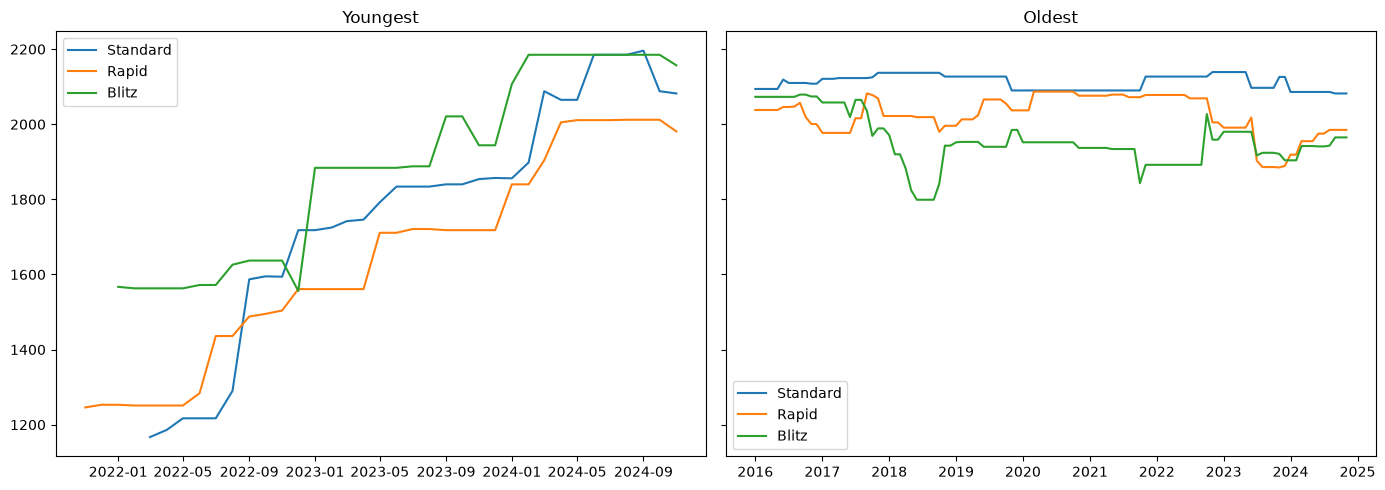


Youngest
  SRTNG: 342.2 pts/year
  RRTNG: 262.5 pts/year
  BRTNG: 208.1 pts/year

Oldest
  SRTNG: 11.3 pts/year
  RRTNG: -14.4 pts/year
  BRTNG: -44.6 pts/year


In [10]:
# Step 1: Find youngest and oldest player
youngest = title_events.loc[title_events["age_at_title"].idxmin()]
oldest = title_events.loc[title_events["age_at_title"].idxmax()]

# Step 2: Get their rating history from fide (2016-2024)
y_hist = female_df[
    (female_df["ID"] == youngest["ID"]) &
    (female_df["DATE"].dt.year >= 2016) &
    (female_df["DATE"].dt.year <= 2024)
].sort_values("DATE")

o_hist = female_df[
    (female_df["ID"] == oldest["ID"]) &
    (female_df["DATE"].dt.year >= 2016) &
    (female_df["DATE"].dt.year <= 2024)
].sort_values("DATE")

# Step 3: Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, hist, label in zip(axes, [y_hist, o_hist], ["Youngest", "Oldest"]):
    ax.plot(hist["DATE"], hist["SRTNG"], label="Standard")
    ax.plot(hist["DATE"], hist["RRTNG"], label="Rapid")
    ax.plot(hist["DATE"], hist["BRTNG"], label="Blitz")
    ax.set_title(label)
    ax.legend()

plt.tight_layout()
plt.show()

# Step 4: Growth rates
for label, hist in [("Youngest", y_hist), ("Oldest", o_hist)]:
    print(f"\n{label}")
    for col in ["SRTNG", "RRTNG", "BRTNG"]:
        r = calculate_growth_rate(hist, col, years=3,
                                  offset=pd.Timestamp("2016-01-01"))
        print(f"  {col}: {r['slope']:.1f} pts/year")


#### Findings

The youngest player was Sivanandan, Bodhana who got her title 
at age 9, and the oldest was Ivanova, Tatiana who got hers 
at age 66.

Looking at the plots, Sivanandan started with a low rating 
and grew very fast, gaining 342.2 points per year in Standard, 
262.5 in Rapid and 208.1 in Blitz. Ivanova barely improved 
or even declined, with Standard at only 11.3 points per year, 
Rapid at -14.4 and Blitz at -44.6 points per year.

This makes sense because younger players have more room to 
improve, while older players are usually already close to 
their peak. These results suggest that age at title may be 
linked to how fast a player grows, which is what section 4 
will test more formally.


### 4. Hypothesis test — do younger WGMs improve faster?

**H1:** *The younger a player is when she earns the Woman Grandmaster (WGM) title, the faster her early-career rating growth.*

- **Population:** players with an observable transition into `WGM` (players whose first record already shows `WGM` are excluded).
- **Early-career growth:** Standard rating change (points/year) over the 3 years after the first `WGM` record.
- **Groups:** split at the median age at title.
- **Test:** one-sided two-sample *t*-test. Significance indicates an association, not causation.


#### Approach

1. Define MASTERS = {"WGM"} to focus only on WGM title events.

2. Apply get_title_events(female_df, MASTERS) to get the first 
   observed WGM transition per player — this excludes players 
   whose first record already had the WGM title.

3. Project title_year from DATE and compute 
   age_at_title = title_year - BORN. Drop rows where 
   age_at_title is null and convert to integer.

4. For each player, compute early-career Standard rating 
   growth using calculate_growth_rate with years=3 and 
   offset=title_date — this measures growth in points per 
   year over the 3 years after earning the WGM title. 
   The 3-year window is applied consistently to all players.

5. Drop players with no valid growth rate, producing 
   growth_df with one row per player.

6. Project median age_at_title to define the group boundary. 
   Split players into two groups: younger (age < median) 
   and older (age >= median). Report the number of players 
   in each group.

7. Apply a one-sided two-sample t-test to explore whether 
   younger WGMs tend to grow faster than older ones:
   H0: mean growth is equal between the two groups.
   H1: younger group has higher mean growth than older group.

8. Plot a boxplot to compare growth rate distributions 
   between the two age groups.


Median age: 22.0
Younger: n=47, mean=2.4 pts/year
Older:   n=56,   mean=-19.6 pts/year
t=2.193, p=0.0153


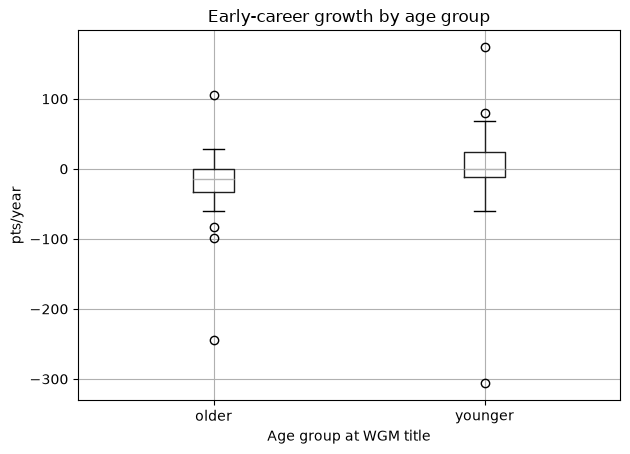

In [11]:
# Step 1: Get WGM title events and compute age
WGM_ONLY = {"WGM"}
wgm_events = get_title_events(female_df, WGM_ONLY)
wgm_events["title_year"] = wgm_events["DATE"].dt.year
wgm_events["age_at_title"] = (
    wgm_events["title_year"] - wgm_events["BORN"]
)
wgm_events = wgm_events.dropna(subset=["age_at_title"])
wgm_events["age_at_title"] = wgm_events["age_at_title"].astype(int)

# Step 2: Compute growth rate per player after title date
growth_rates = []
for _, player in wgm_events.iterrows():
    hist = female_df[female_df["ID"] == player["ID"]]
    r = calculate_growth_rate(hist, "SRTNG", years=3,
                              offset=player["DATE"])
    growth_rates.append({"ID": player["ID"],
                         "age_at_title": player["age_at_title"],
                         "slope": r["slope"]})

growth_df = pd.DataFrame(growth_rates).dropna(subset=["slope"])
assert growth_df["ID"].nunique() == len(growth_df)

# Step 3: Split by median age
median_age = growth_df["age_at_title"].median()
younger = growth_df[growth_df["age_at_title"] <  median_age]["slope"]
older   = growth_df[growth_df["age_at_title"] >= median_age]["slope"]

# Step 4: One-sided t-test
# H0: mean growth is equal between groups
# H1: younger group grows faster than older group
t_stat, p_value = stats.ttest_ind(younger, older, alternative="greater")
print(f"Median age: {median_age}")
print(f"Younger: n={len(younger)}, mean={younger.mean():.1f} pts/year")
print(f"Older:   n={len(older)},   mean={older.mean():.1f} pts/year")
print(f"t={t_stat:.3f}, p={p_value:.4f}")

# Step 5: Boxplot
growth_df["group"] = np.where(
    growth_df["age_at_title"] < median_age, "younger", "older"
)
growth_df.boxplot(column="slope", by="group")
plt.title("Early-career growth by age group")
plt.suptitle("")
plt.xlabel("Age group at WGM title")
plt.ylabel("pts/year")
plt.tight_layout()
plt.show()

#### Findings

To test H1, only WGM players with an observable title transition 
were included. Early-career growth was defined as the change in 
Standard rating over the 3 years after earning the WGM title, 
in points per year. This window was applied to all players 
the same way.

Players were split at the median age of 22 years. The younger 
group (age < 22, n=47) had a mean growth of 2.4 points per year. 
The older group (age >= 22, n=56) had a mean of -19.6 points per 
year, meaning older WGMs actually declined on average after 
earning their title. This suggests that older players were 
already close to their rating peak when they got the title.

A one-sided t-test gave t=2.193 and p=0.0153. Since p < 0.05 
we reject H0 and the data supports H1. Younger WGMs tend to 
grow faster in the early career than older ones. However this 
is only an association within this dataset and does not mean 
that being young causes faster rating growth.


## ♗ Part 2 — Federations


### 5. Female players per federation

Count female players per federation using each player's **latest** record (one row per player, not per player–month),
and report each federation's share of the total.


#### Approach


1. Select female-only records from female_df (section 1 result).

2. Aggregate by ID to find the maximum DATE per player — 
   this produces one row per player with their latest date.

3. Join the latest date back to female_df on ID and DATE — 
   this produces one row per player at their latest record.

4. Assert exactly one row per player after the join.

5. Aggregate by FED and count distinct players — this produces 
   the total number of female players per federation.

6. Project a proportion column as each federation's share 
   of the total female player population.

7. Sort federations in descending order by player count.

8. Plot a bar chart of the top 20 federations.


FED  player_count  proportion
RUS          9918    0.149017
IND          6184    0.092914
FRA          3639    0.054676
POL          2782    0.041799
GER          2427    0.036466
ESP          2397    0.036015
IRI          2216    0.033295
SRI          1568    0.023559
BRA          1470    0.022087
UKR          1397     0.02099

Top 5 federations account for 37.5% of all female players


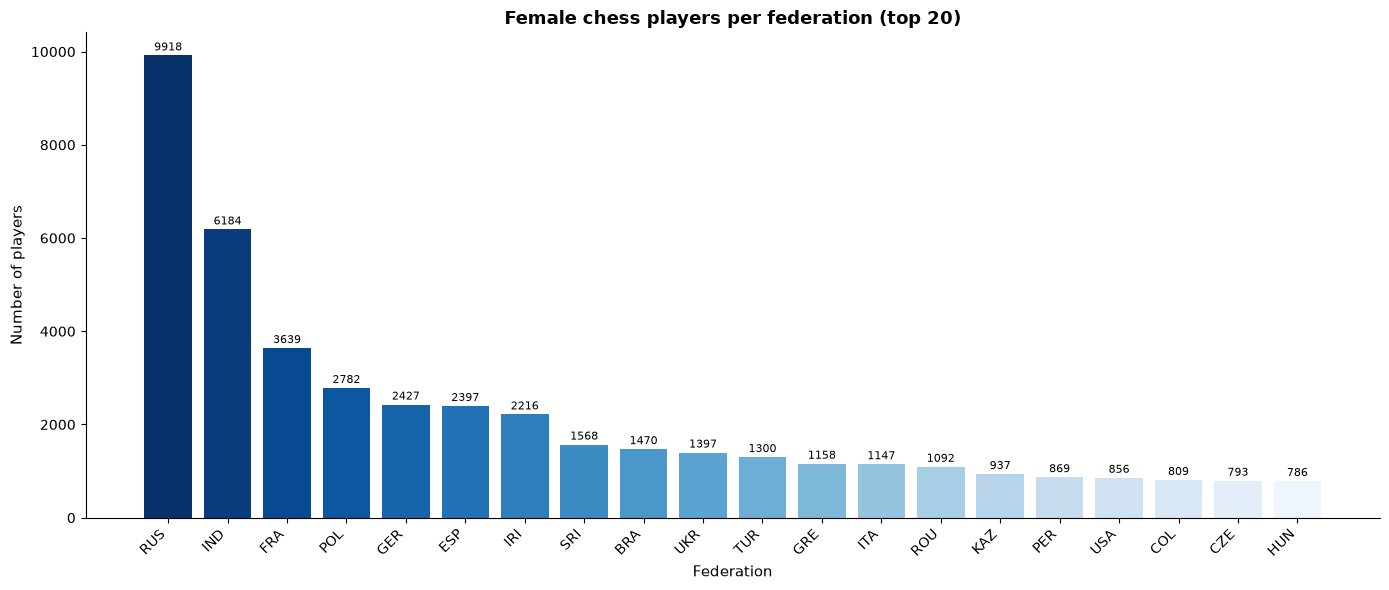

In [12]:
# Get each player's latest available record using sort and dedup
latest = (
    female_df.sort_values("DATE")
    .drop_duplicates(subset=["ID"], keep="last")
)

# Validate exactly one row per player
assert latest["ID"].nunique() == len(latest)

# Count players per federation and rank in descending order
fed_counts = (
    latest.groupby("FED")["ID"]
    .count()
    .reset_index()
    .rename(columns={"ID": "player_count"})
    .sort_values("player_count", ascending=False)
)

# Add proportion column to show each federation's share
fed_counts["proportion"] = (
    fed_counts["player_count"] / fed_counts["player_count"].sum()
)

# Print top 10 results
print(fed_counts.head(10).to_string(index=False))
top5_pct = fed_counts.head(5)["proportion"].sum() * 100
print(f"\nTop 5 federations account for {top5_pct:.1f}% of all female players")

# Plot top 20 federations
top20 = fed_counts.head(20)
colors = plt.cm.Blues_r(
    [i / len(top20) for i in range(len(top20))]
)

fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.bar(top20["FED"], top20["player_count"], color=colors)

# Add value labels on top of each bar
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        str(int(bar.get_height())),
        ha="center", va="bottom", fontsize=8
    )

ax.set_xlabel("Federation", fontsize=11)
ax.set_ylabel("Number of players", fontsize=11)
ax.set_title("Female chess players per federation (top 20)",
             fontsize=13, fontweight="bold")
ax.set_xticks(range(len(top20)))
ax.set_xticklabels(top20["FED"], rotation=45, ha="right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

#### Findings
Russia has the most female players with 9,918, followed by 
India with 6,184. The top five federations together account for 
37.5% of all female players, indicating that a substantial share 
of female players are concentrated in a small number of countries.

It is also interesting to see India and Iran in the top 10, 
since these are not traditionally seen as chess powerhouses 
in Europe. Most other countries have much smaller numbers 
of female players compared to the top five.


### 6. Federation growth, 2015 → 2024

Growth is measured as the average number of female players added per year:

\begin{equation}
\frac{N_{2024} - N_{2015}}{9}
\end{equation}

where $N$ is the number of distinct female players observed in that calendar year.


#### Approach

1. Select records from female_df where DATE.year = 2015 — 
   this produces the starting population.

2. Aggregate by FED and count distinct players in 2015 — 
   this produces N_start per federation.

3. Select records from female_df where DATE.year = 2024 — 
   this produces the ending population.

4. Aggregate by FED and count distinct players in 2024 — 
   this produces N_end per federation.

5. Join N_start and N_end on FED — this produces one row 
   per federation with both counts.

6. Project growth rate = (N_end - N_start) / 9 for each 
   federation, where 9 = 2024 - 2015.

7. Sort federations in descending order by growth rate.

8. Plot a bar chart of the top 20 fastest growing federations.


     n_start   n_end  growth_rate
FED                              
RUS   3881.0  9823.0   660.222222
IND   2077.0  6056.0   442.111111
FRA   1329.0  3556.0   247.444444
IRI    486.0  2185.0   188.777778
ESP    863.0  2355.0   165.777778
POL   1239.0  2730.0   165.666667
GER   1199.0  2425.0   136.222222
BRA    365.0  1460.0   121.666667
SRI    529.0  1521.0   110.222222
UKR    474.0  1378.0   100.444444


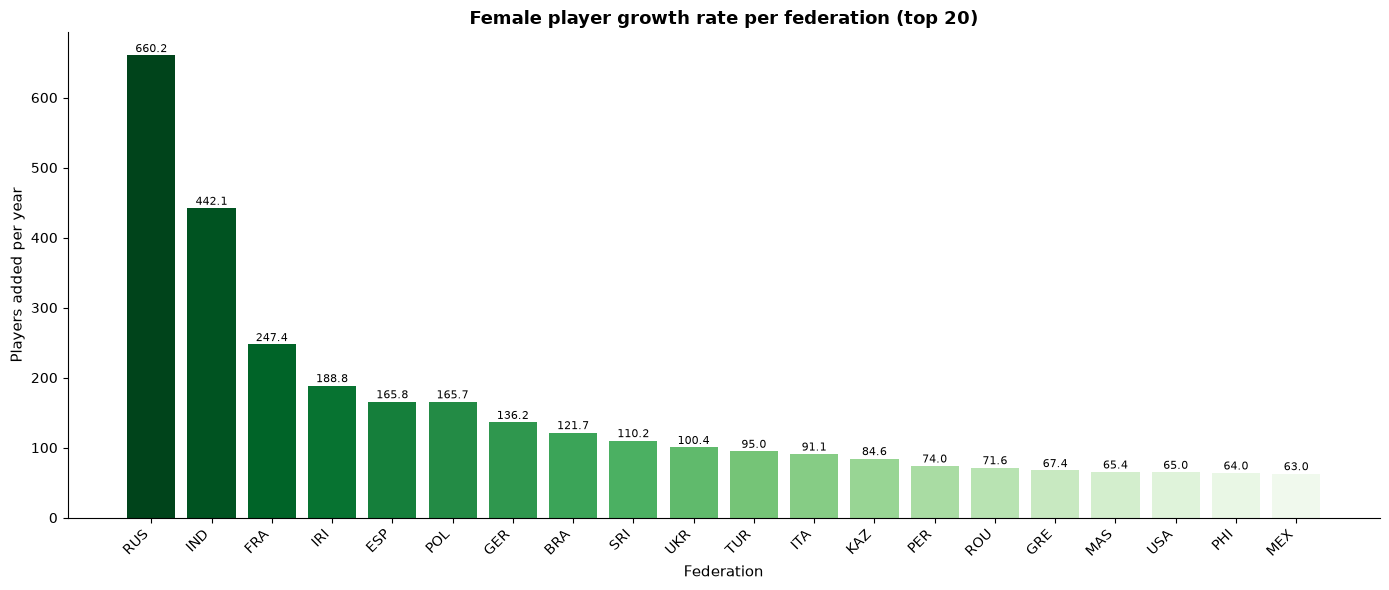

In [13]:
# Select players appearing in 2015 and 2024
start_year = female_df[female_df["DATE"].dt.year == 2015]
end_year   = female_df[female_df["DATE"].dt.year == 2024]

# Count distinct players per federation in each year
start_counts = (
    start_year.groupby("FED")["ID"]
    .nunique()
    .rename("n_start")
)

end_counts = (
    end_year.groupby("FED")["ID"]
    .nunique()
    .rename("n_end")
)

# Join and compute average annual growth rate
growth = pd.concat([start_counts, end_counts], axis=1).fillna(0)
growth["growth_rate"] = (growth["n_end"] - growth["n_start"]) / 9

# Sort by growth rate descending
growth = growth.sort_values("growth_rate", ascending=False)
print(growth.head(10).to_string())

# Plot top 20 federations by growth rate
top20 = growth.head(20)
colors = plt.cm.Greens_r(
    [i / len(top20) for i in range(len(top20))]
)

fig, ax = plt.subplots(figsize=(14, 6))
x = range(len(top20))
bars = ax.bar(x, top20["growth_rate"], color=colors)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.1f}",
        ha="center", va="bottom", fontsize=8
    )

ax.set_xticks(x)
ax.set_xticklabels(top20.index, rotation=45, ha="right")
ax.set_xlabel("Federation", fontsize=11)
ax.set_ylabel("Players added per year", fontsize=11)
ax.set_title("Female player growth rate per federation (top 20)",
             fontsize=13, fontweight="bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

#### Findings

Russia grows the fastest, adding about 660 female players per 
year between 2015 and 2024. India comes second with 442 players 
per year. France, Iran and Spain also grew quite fast compared 
to other countries.

This makes sense because Russia and India were already the 
biggest federations in section 5, so they are both large and 
still growing. Iran is interesting because it was not in the 
top 3 for total players but is growing very fast, which means 
it could move higher in the rankings in the future.

The growth rate here is a simple average over 9 years, so it 
does not capture years where growth was faster or slower.


### 7. Federation transfers — which federations are "talent magnets"?

A transfer is a change in `FED` between two consecutive records of the same player. Only each player's **first**
transfer is counted, so no player is counted twice. Net inflow per federation is

\begin{equation}
\text{Net inflow}_f = \text{Inbound}_f - \text{Outbound}_f
\end{equation}


#### Approach

1. Select female-only records from female_df and sort by 
   ID and DATE — this produces an ordered relation of 
   player-month observations.

2. Project a new column previousFED by shifting the FED 
   column within each player group — this produces a 
   relation where each row has both current and previous 
   federation.

3. Select rows where previousFED is not missing AND 
   FED != previousFED — this produces all federation 
   transition events.

4. Assert no transitions where previousFED is missing.

5. Keep only the first transition per player — this avoids 
   counting the same player multiple times and gives a 
   cleaner picture of migration patterns.

6. Aggregate by (previousFED, FED) and count transitions — 
   this produces a transition table with columns 
   fromFED, toFED and count.

7. Compute net inflow per federation as inbound - outbound 
   — this identifies which federations attract more players 
   than they lose.

8. Plot a bar chart of top federations by net inflow to 
   visualise which federations act as talent magnets.


previousFED FED  count
        BUL FID    258
        RUS FID    151
        SIN SGP     71
        BLR FID     38
        FID BUL     17
        LIB LBN     14
        UKR GER     13
        IND USA      8
        UKR RUS      7
        BLR POL      6


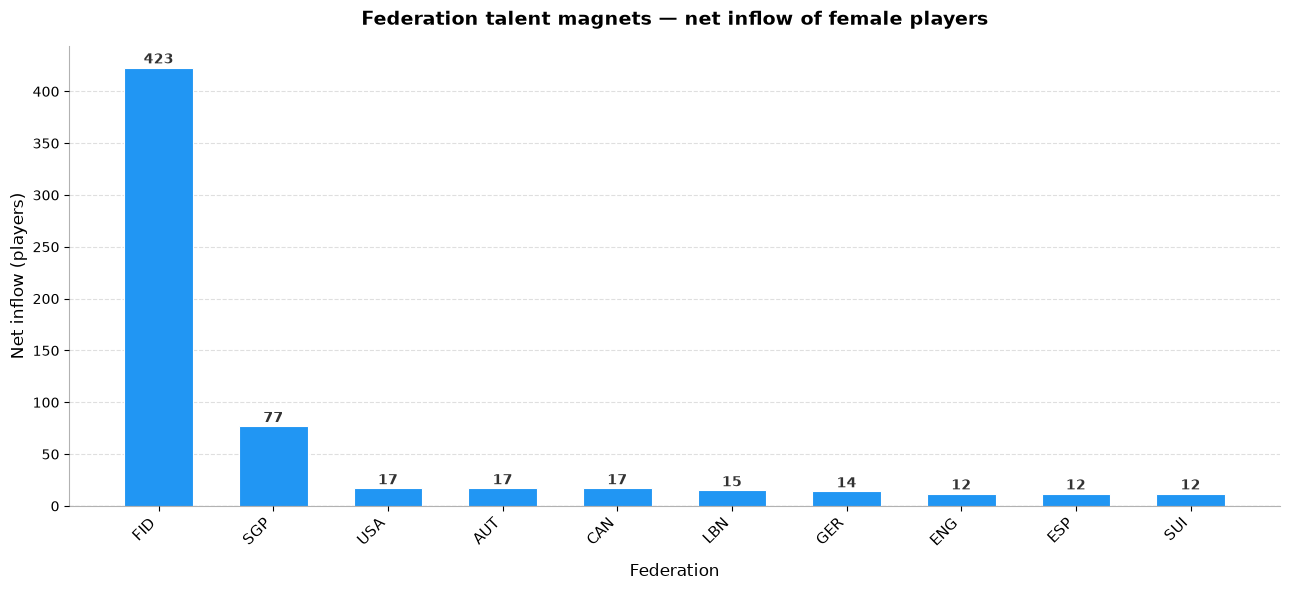

In [14]:
# Sort by ID and DATE and compute previous federation
data = female_df.sort_values(["ID", "DATE"]).copy()
data["previousFED"] = data.groupby("ID")["FED"].shift(1)

# Select only federation transition events
transitions = data[
    data["previousFED"].notna() &
    (data["FED"] != data["previousFED"])
].copy()

# Keep only first transition per player
first_transfers = transitions.drop_duplicates(
    subset=["ID"], keep="first"
)

# Validate no missing previousFED
assert first_transfers["previousFED"].notna().all()

# Count transitions between federation pairs
flows = (
    first_transfers.groupby(["previousFED", "FED"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)
print(flows.head(10).to_string(index=False))

# Compute net inflow per federation
inbound = (
    first_transfers.groupby("FED")["ID"]
    .count()
    .rename("inbound")
)
outbound = (
    first_transfers.groupby("previousFED")["ID"]
    .count()
    .rename("outbound")
)
net_inflow = pd.concat([inbound, outbound], axis=1).fillna(0)
net_inflow["net_inflow"] = (
    net_inflow["inbound"] - net_inflow["outbound"]
)
net_inflow = net_inflow.sort_values("net_inflow", ascending=False)

# Plot net inflow bar chart
top10 = net_inflow.head(10)
fig, ax = plt.subplots(figsize=(13, 6))
x = range(len(top10))

colors = [
    "#2196F3" if v >= 0 else "#EF5350"
    for v in top10["net_inflow"]
]
bars = ax.bar(x, top10["net_inflow"], color=colors,
              edgecolor="white", linewidth=0.8, width=0.6)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.8,
        str(int(height)),
        ha="center", va="bottom",
        fontsize=10, fontweight="bold",
        color="#333333"
    )

# Add horizontal line at zero
ax.axhline(0, color="gray", linewidth=0.8, linestyle="--")

ax.set_xticks(x)
ax.set_xticklabels(top10.index, rotation=45,
                   ha="right", fontsize=11)
ax.set_xlabel("Federation", fontsize=12, labelpad=10)
ax.set_ylabel("Net inflow (players)", fontsize=12)
ax.set_title(
    "Federation talent magnets — net inflow of female players",
    fontsize=14, fontweight="bold", pad=15
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_alpha(0.3)
ax.spines["bottom"].set_alpha(0.3)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

#### Findings

To find federation changes, only the first transfer per player 
was counted so that the same player is not counted twice.

Ignoring FID (players competing under the FIDE flag, e.g. during a federation
suspension or sanctions), which is not a country, Singapore has the 
highest net inflow with +77 players. This means 77 more players 
moved to Singapore than left it. The USA, Austria and Canada 
follow with around +17 each.

These federations attract more players than they lose, so they 
can be seen as talent magnets. This could be because they offer 
better chess training or because players move there for work 
or study.

Overall, very few players changed federation compared to the 
total of 66,556 female players, suggesting that most players 
remain registered under the same federation within the observed period.


### 8. Hypothesis test — title volume vs recipient age

**H2:** *Federations that award more female Master/Grandmaster titles per year tend to have younger title recipients.*

Tested with a Pearson correlation at the federation level.


#### Approach

1. Select title events from the events table produced in 
   section 2 — this contains one row per female player with 
   an inferred master-level title transition.

2. Aggregate by FED and count total titles per federation 
   — this produces total_titles per federation.

3. Project titles_per_year = total_titles / 9 for each 
   federation, where 9 = 2024 - 2015.

4. Aggregate by FED and compute mean age_at_title per 
   federation — this produces mean_age per federation.

5. Join titles_per_year and mean_age on FED — this produces 
   one row per federation with both measures.

6. Select federations with at least 5 title events to 
   remove noise from very small federations.

7. Compute Pearson correlation between titles_per_year 
   and mean_age to explore whether a negative association 
   exists — H0 is no correlation, H1 is negative 
   correlation (more titles = younger recipients).

8. Plot a scatter chart of titles_per_year vs mean_age 
   with federation labels.


Federations in analysis: 53
FED  titles_per_year  mean_age
RUS        12.222222 19.945455
IND         7.333333 19.151515
USA         5.222222 14.085106
POL         3.888889 21.114286
CUB         3.333333 18.733333
ESP         3.111111 19.285714
CHN         2.666667 21.166667
GER         2.333333 20.428571
KAZ         2.111111 17.263158
AZE              2.0 21.222222

Pearson correlation: -0.059
P-value: 0.6763


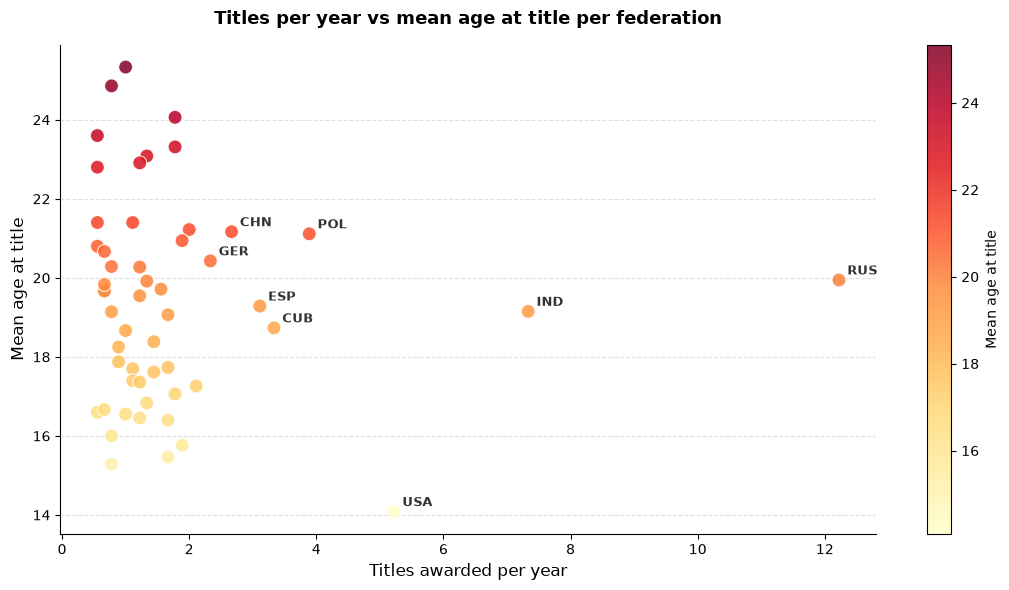

In [15]:
# Compute titles per year per federation
titles_per_year = (
    title_events.groupby("FED")["ID"]
    .count()
    .reset_index(name="total_titles")
)
titles_per_year["titles_per_year"] = (
    titles_per_year["total_titles"] / 9
)

# Compute mean age at title per federation
mean_age = (
    title_events.groupby("FED")["age_at_title"]
    .mean()
    .reset_index(name="mean_age")
)

# Join and filter federations with at least 5 title events
fed_summary = titles_per_year.merge(mean_age, on="FED")
fed_summary = fed_summary[fed_summary["total_titles"] >= 5]
print(f"Federations in analysis: {len(fed_summary)}")
print(fed_summary[["FED", "titles_per_year", "mean_age"]]
      .sort_values("titles_per_year", ascending=False)
      .head(10)
      .to_string(index=False))

# H0: no correlation between titles per year and mean age
# H1: negative correlation (more titles = younger recipients)
corr, p_value = stats.pearsonr(
    fed_summary["titles_per_year"],
    fed_summary["mean_age"]
)
print(f"\nPearson correlation: {corr:.3f}")
print(f"P-value: {p_value:.4f}")

# Scatter plot coloured by mean age
fig, ax = plt.subplots(figsize=(11, 6))
sc = ax.scatter(
    fed_summary["titles_per_year"],
    fed_summary["mean_age"],
    c=fed_summary["mean_age"],
    cmap="YlOrRd",
    alpha=0.85,
    edgecolors="white",
    linewidths=0.8,
    s=100
)

plt.colorbar(sc, ax=ax, label="Mean age at title")

# Label top federations by titles per year
top_feds = fed_summary.nlargest(8, "titles_per_year")
for _, row in top_feds.iterrows():
    ax.annotate(
        row["FED"],
        (row["titles_per_year"], row["mean_age"]),
        textcoords="offset points",
        xytext=(6, 4), fontsize=9,
        color="#333333", fontweight="bold"
    )

ax.set_xlabel("Titles awarded per year", fontsize=12)
ax.set_ylabel("Mean age at title", fontsize=12)
ax.set_title(
    "Titles per year vs mean age at title per federation",
    fontsize=13, fontweight="bold", pad=15
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

#### Findings


The analysis included 53 federations with at least 5 title 
events. Federations with fewer than 5 events were excluded 
to avoid noise from very small samples.

The Pearson correlation is -0.059 with a p-value of 0.6763. 
Since p > 0.05 the result is not significant and H2 is not 
supported by the data. There is no clear evidence that 
federations awarding more titles per year have younger 
recipients on average.

Looking at the top federations, Russia and India award the 
most titles per year with mean ages around 19 to 20 years. 
The USA has the youngest mean age at 14 but is only third 
in titles per year. This suggests that the relationship between 
title volume and recipient age may not be straightforward and 
could depend on additional factors such as player development 
systems and federation size.


## ♖ Part 3 — Online play (chess.com)

chess.com accounts are linked to FIDE profiles through a username → FIDE ID mapping, to examine whether online
activity corresponds to over-the-board performance. The loaders below normalise usernames, attach FIDE IDs to
both sides of each game and print a coverage report.


In [16]:
def load_games(path: str) -> pd.DataFrame:
    """
    Loads chess.com games dataset.
    """
    games = pd.read_csv(path, compression="gzip", low_memory=False)
    
    for column in ["wgm_username", "white_username", "black_username"]:

        # Unlikely error
        assert column in games.columns, f"Missing column {column}"

        # Convert usernames to lowercase and strip whitespace
        games[column] = (
            games[column].astype("string").str.strip().str.lower()
        )
    
    # Parse game date
    games["game_date"] = pd.to_datetime(games["end_time"], errors="coerce")

    # Unlikely error
    assert games["game_date"].notna().any(), "Invalid game dates"
    
    return games


def load_mapping(path: str) -> pd.DataFrame:
    """
    Loads mapping of chess.com usernames to FIDE IDs.
    """
    df = pd.read_csv(path, low_memory=False)
    # Project useful columns
    df = df[["username", "fid"]].copy()
    # Rename 'fid' to 'ID' to match FIDE dataset
    df = df.rename(columns={"fid": "ID"})
    # Convert ID to numeric, coercing errors
    df["ID"] = pd.to_numeric(df["ID"], errors="coerce").astype("Int64")
    # Normalize usernames, matching the games dataset 
    # (lowercase, stripped of whitespace)
    df["username"] = df["username"].astype("string").str.strip().str.lower()
    # Unlikely errors
    df = df.dropna(subset=["username", "ID"]).drop_duplicates(subset=["username"])
    return df


def mymap(games: pd.DataFrame, mapping: pd.DataFrame) -> pd.DataFrame:
    """
    Assigns FIDE ID for white/black players (if present in mapping).

    New columns "whiteID" and "blackID" are added to the games DataFrame.
    """
    df = games.copy()

    # Merge to get white player ID
    df = df.merge(
        mapping.rename(columns={"username": "white_username", "ID": "whiteID"}),
        on="white_username",
        how="left",
    )

    # Merge to get black player ID
    df = df.merge(
        mapping.rename(columns={"username": "black_username", "ID": "blackID"}),
        on="black_username",
        how="left",
    )

    return df


def info(games: pd.DataFrame) -> str:
    
    # Total number of games
    ngames = len(games)

    # Number of games with with known white player
    nwhite = games["whiteID"].notna().sum()

    # Number of games with with known black player
    nblack = games["blackID"].notna().sum()

    # Number of games with at least one known player
    nany = (games["whiteID"].notna() | games["blackID"].notna()).sum()

    # Number of games with both players known
    nboth = (games["whiteID"].notna() & games["blackID"].notna()).sum()

    # Unique mapped FIDE players appearing in games
    nplayers = pd.concat([games["whiteID"], games["blackID"]]).dropna().unique()

    s = "Coverage Report\n"
    s += (f"\t{ngames:7,d} total games\n")
    s += (f"\t{nwhite:7,d} ({nwhite/ngames:6.2%}) games with mapped white\n")
    s += (f"\t{nblack:7,d} ({nblack/ngames:6.2%}) games with mapped black\n")
    s += (f"\t{nany:7,d} ({nany/ngames:6.2%}) games with any mapped player\n")
    s += (f"\t{nboth:7,d} ({nboth/ngames:6.2%}) games with both players mapped\n")
    s += (f"\t{len(nplayers):7,d} unique mapped FIDE players appearing in games\n")

    s += f"\n\tGames from {games['game_date'].min()} to {games['game_date'].max()}"

    return s


games = load_games("../data/chesscom_games.csv.gz")
mapping = load_mapping("../data/chesscom_fide_mapping.csv")

games_mapped = mymap(games, mapping)
print(info(games_mapped))

Coverage Report
	304,767 total games
	 39,138 (12.84%) games with mapped white
	 39,048 (12.81%) games with mapped black
	 77,804 (25.53%) games with any mapped player
	    382 ( 0.13%) games with both players mapped
	     12 unique mapped FIDE players appearing in games

	Games from 2009-09-10 18:11:28 to 2021-02-01 07:55:02


### 9. Most active online players

Rank female masters and grandmasters with a linked chess.com account by number of online games.


#### Approach

1. Project all mapped FIDE player IDs from games_mapped by 
   combining whiteID and blackID columns — this produces a 
   set of 12 unique mapped player IDs.

2. Select games where whiteID is in mapped_ids and count 
   games per player — this produces white game counts per 
   player.

3. Select games where blackID is in mapped_ids and count 
   games per player — this produces black game counts per 
   player.

4. Join white and black game counts on ID and sum them — 
   this produces total_games per player.

5. Select player details from fide using mapped_ids and 
   keep only the latest record per player — this produces 
   NAME, TITLE and FED for each mapped player.

6. Join game counts with player details on ID — this 
   produces one row per player with total games and 
   player information.

7. Sort by total_games in descending order to rank players.


In [17]:
# Get female masters and grandmasters from fide
female_masters = (
    female_df[female_df["TITLE"].isin(
        ["WGM", "WIM", "WFM", "FM", "IM", "GM"]
    )]
    [["ID", "NAME", "TITLE"]]
    .drop_duplicates(subset=["ID"])
)

# Join with mapping to find players with chess.com accounts
masters_mapped = female_masters.merge(mapping, on="ID", how="inner")
print(f"Players with chess.com account: {len(masters_mapped)}")
print(masters_mapped[["ID", "NAME", "TITLE"]].to_string(index=False))

# Get mapped player IDs
mapped_ids = set(masters_mapped["ID"].astype("int64"))

# Count games as white per player ID
white_games = (
    games_mapped[games_mapped["whiteID"]
                 .astype("int64", errors="ignore")
                 .isin(mapped_ids)]
    .groupby("whiteID")["whiteID"].count()
    .rename("games").rename_axis("ID")
)

# Count games as black per player ID
black_games = (
    games_mapped[games_mapped["blackID"]
                 .astype("int64", errors="ignore")
                 .isin(mapped_ids)]
    .groupby("blackID")["blackID"].count()
    .rename("games").rename_axis("ID")
)

# Combine and compute total games per player ID
game_counts = (
    pd.concat([white_games, black_games])
    .groupby("ID").sum()
    .reset_index()
)
game_counts["ID"] = game_counts["ID"].astype("int64")

# Attach player details and rank by total games
player_info = (
    fide[fide["ID"].astype("int64", errors="ignore")
         .isin(mapped_ids)]
    .sort_values("DATE")
    .drop_duplicates(subset=["ID"], keep="last")
    [["ID", "NAME", "TITLE", "FED"]]
).copy()
player_info["ID"] = player_info["ID"].astype("int64")

ranked = (
    game_counts.merge(player_info, on="ID", how="left")
    .sort_values("games", ascending=False)
    [["ID", "NAME", "TITLE", "FED", "games"]]
    .reset_index(drop=True)
)

print(ranked.to_string(index=False))

Players with chess.com account: 12
      ID                 NAME TITLE
  505161           Zhou, Qiyu   WFM
  739049          Papp, Petra   WGM
 2908689    Nikolova, Adriana   WGM
 4120876        Turova, Irina    IM
 4162340      Tomilova, Elena   WIM
12401102  Hoang, Thi Bao Tram   WGM
12401838    Vo, Thi Kim Phung   WIM
13300270     Gevorgyan, Maria   WFM
14112035 Doluhanova, Evgeniya   WGM
14117258       Kalinina, Olga   WGM
14117665      Soloviova, Liza   WGM
24142654      Belenkaya, Dina   WFM
      ID                 NAME TITLE FED  games
12401838    Vo, Thi Kim Phung   WGM VIE  28945
 2908689    Nikolova, Adriana   WGM BUL  13277
14117665 Malakhova, Elizaveta   WGM UKR   9463
12401102  Hoang, Thi Bao Tram   WGM VIE   8944
  505161           Zhou, Qiyu    FM CAN   6315
14112035 Doluhanova, Evgeniya   WGM UKR   3079
24142654      Belenkaya, Dina   WGM ISR   2572
  739049          Papp, Petra   WGM HUN   1820
13300270     Gevorgyan, Maria   WGM ARM   1703
14117258          Babiy, Ol

#### Findings

The mapping dataset contains 12 female masters and 
grandmasters with chess.com accounts. Their IDs range 
from 505161 to 24142654.

Vo, Thi Kim Phung (ID: 12401838, WGM, Vietnam) is the 
most active player with 28,945 games, followed by 
Nikolova, Adriana (ID: 2908689, WGM, Bulgaria) with 
13,277 and Soloviova, Liza (ID: 14117665, WGM, Ukraine) 
with 9,463 games.

Ukraine has three players in the top 10 (IDs: 14117665, 
14112035, 14117258), making it the most represented 
country. At the bottom, Turova, Irina (ID: 4120876, IM, 
Russia) has only 165 games, showing that not all mapped 
players are equally active online.

The small sample of 12 players is a major limitation and 
results cannot be generalised to all female masters and 
grandmasters.


### 10. Does online activity vary by age or federation?


#### Approach

We operationalise online gaming preference as the total number 
of online games played in the dataset, since it reflects how 
often a player chooses to play online.

1. Select records from fide where ID ∈ mapped_ids —
   this produces BORN and FED for each mapped player.

2. Drop duplicates by ID keeping the latest DATE —
   this produces one row per player.

3. Join with game_counts from section 9 on ID —
   this produces one row per player with total_games,
   BORN and FED.

4. Compute age = 2021 - BORN for each player —
   2021 is the last year in the games dataset.

5. Drop rows where age or total_games is null.

6. Compute Pearson correlation between age and total_games
   to explore whether age is associated with online activity.

7. Aggregate by FED and compute mean total_games per
   federation — this produces one row per federation.

8. Plot a scatter chart of age vs total_games.

9. Plot a bar chart of mean total_games per federation.


                NAME  age FED  games
   Vo, Thi Kim Phung 28.0 VIE  28945
   Nikolova, Adriana 33.0 BUL  13277
Malakhova, Elizaveta 28.0 UKR   9463
 Hoang, Thi Bao Tram 34.0 VIE   8944
          Zhou, Qiyu 21.0 CAN   6315
Doluhanova, Evgeniya 37.0 UKR   3079
     Belenkaya, Dina 28.0 ISR   2572
         Papp, Petra 28.0 HUN   1820
    Gevorgyan, Maria 27.0 ARM   1703
         Babiy, Olga 32.0 UKR   1430
     Tomilova, Elena 35.0 RUS    473
       Turova, Irina 42.0 RUS    165

Correlation (age vs games): -0.256, p=0.4227
FED    avg_games
VIE      18944.5
BUL      13277.0
CAN       6315.0
UKR  4657.333333
ISR       2572.0
HUN       1820.0
ARM       1703.0
RUS        319.0


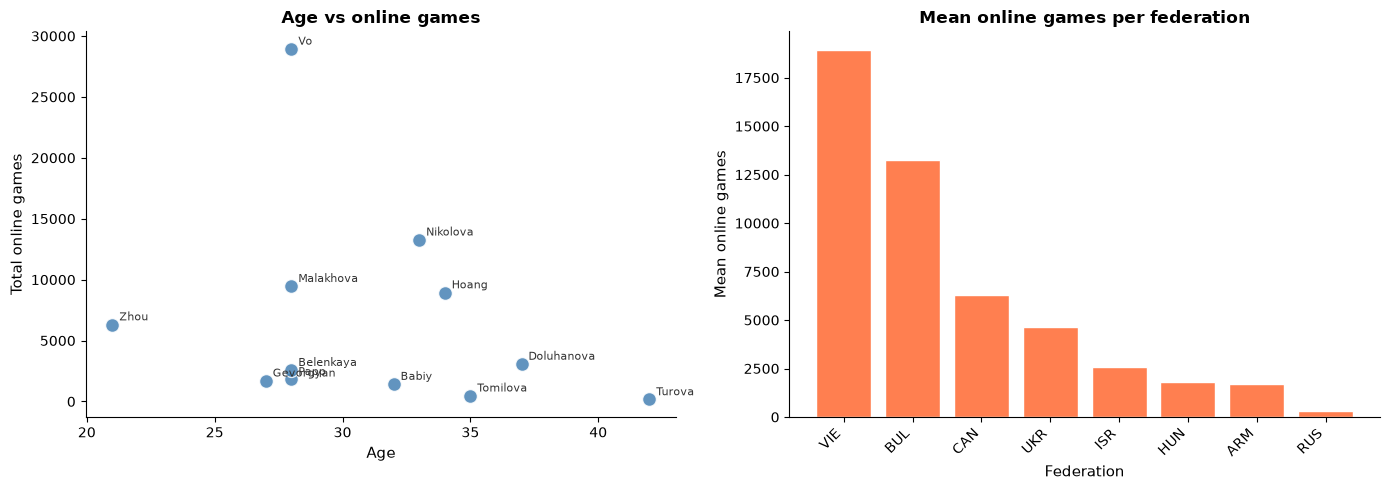

In [18]:
# Get player demographics from fide
player_info = (
    fide[fide["ID"].astype("int64", errors="ignore")
         .isin(mapped_ids)]
    .sort_values("DATE")
    .drop_duplicates(subset=["ID"], keep="last")
    [["ID", "NAME", "BORN", "FED"]]
).copy()
player_info["ID"] = player_info["ID"].astype("int64")

# Join with game counts from section 9
analysis = game_counts.merge(player_info, on="ID", how="left")

# Compute age using last year in games dataset
reference_year = 2021
analysis["age"] = reference_year - analysis["BORN"].astype("float")
analysis = analysis.dropna(subset=["age", "games"])

print(analysis[["NAME", "age", "FED", "games"]]
      .sort_values("games", ascending=False)
      .to_string(index=False))

# Correlation between age and total games
corr, pval = stats.pearsonr(analysis["age"], analysis["games"])
print(f"\nCorrelation (age vs games): {corr:.3f}, p={pval:.4f}")

# Mean games per federation
fed_activity = (
    analysis.groupby("FED")["games"]
    .mean()
    .reset_index(name="avg_games")
    .sort_values("avg_games", ascending=False)
)
print(fed_activity.to_string(index=False))

# Plot 1: scatter age vs total games
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    analysis["age"], analysis["games"],
    color="steelblue", edgecolors="white",
    s=100, alpha=0.85
)
for _, row in analysis.iterrows():
    axes[0].annotate(
        row["NAME"].split(",")[0],
        (row["age"], row["games"]),
        textcoords="offset points",
        xytext=(5, 3), fontsize=8, color="#333333"
    )
axes[0].set_xlabel("Age", fontsize=11)
axes[0].set_ylabel("Total online games", fontsize=11)
axes[0].set_title("Age vs online games", fontsize=12,
                   fontweight="bold")
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# Plot 2: bar chart federation vs mean games
x = range(len(fed_activity))
axes[1].bar(x, fed_activity["avg_games"],
            color="coral", edgecolor="white")
axes[1].set_xticks(x)
axes[1].set_xticklabels(fed_activity["FED"],
                         rotation=45, ha="right")
axes[1].set_xlabel("Federation", fontsize=11)
axes[1].set_ylabel("Mean online games", fontsize=11)
axes[1].set_title("Mean online games per federation",
                   fontsize=12, fontweight="bold")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

#### Findings

The analysis included all 12 mapped players. The correlation 
between age and total games is -0.256 with p=0.4227. Since 
p > 0.05 the result is not significant, meaning there is no 
strong evidence that age affects how many online games a 
player plays.

Looking at the scatter plot, Vo Thi Kim Phung stands out 
with 28,945 games at age 28, while Turova, Irina has only 
165 games at age 42. However the pattern is not consistent 
across all players.

At the federation level, Vietnam has the highest mean games 
per player, followed by Bulgaria and Canada. Ukraine has 
three players in the dataset but a lower mean than Vietnam 
because its players have more varied activity levels.

The sample of only 12 players is too small to draw strong 
conclusions about whether age or federation explain online 
gaming preference.


### 11. Online performance vs Elo expectation

For each online game, attach each player's most recent FIDE Standard rating **strictly before** the game date,
compute the Elo expected score and compare it with the actual result. A positive mean delta means the player
scores better online than her FIDE rating predicts.


#### Approach

1. Select games from games_mapped where at least one 
   player ID is in mapped_ids — this produces games 
   with at least one known player.

2. Select FIDE Standard ratings (SRTNG) for mapped_ids 
   and drop rows where SRTNG is null — this produces 
   a clean ratings table with ID, DATE and SRTNG.

3. For each game and each mapped player, attach the most 
recent FIDE Standard rating strictly prior to the 
game date — this produces one rating per player 
per game.

4. Select only games where both white and black FIDE 
   ratings are available.

5. Compute expected score for white player using Elo 
   formula: E = 1 / (1 + 10^((R_black - R_white) / 400))

6. Drop chess-variant games (bughouse, three-check, king of the
   hill), then map the actual result to a score: `win` = 1, draw
   codes (`agreed`, `repetition`, `stalemate`, ...) = 0.5, every
   other code (`checkmated`, `resigned`, `timeout`, ...) = 0.

7. Compute performance delta = actual - expected 
   for each game.

8. Aggregate by player ID and compute mean delta and 
   game count — this produces one row per player.

9. Select players with at least 5 games to filter 
   noise — this produces reliable over/underperformers.

10. Sort by mean delta to identify consistent 
    overperformers (positive) and underperformers 
    (negative).


Games with both FIDE ratings: 382
                NAME       ID  mean_delta  n_games
     Tomilova, Elena  4162340    0.344986       16
      Kalinina, Olga 14117258    0.316798       14
 Hoang, Thi Bao Tram 12401102    0.302714       38
         Papp, Petra   739049    0.269614       26
    Gevorgyan, Maria 13300270    0.223666        6
          Zhou, Qiyu   505161    0.207740       18
     Soloviova, Liza 14117665    0.097380       46
   Vo, Thi Kim Phung 12401838    0.079678       90
       Turova, Irina  4120876    0.052373       18
     Belenkaya, Dina 24142654   -0.052208       36
Doluhanova, Evgeniya 14112035   -0.106004       18
   Nikolova, Adriana  2908689   -0.199355       56


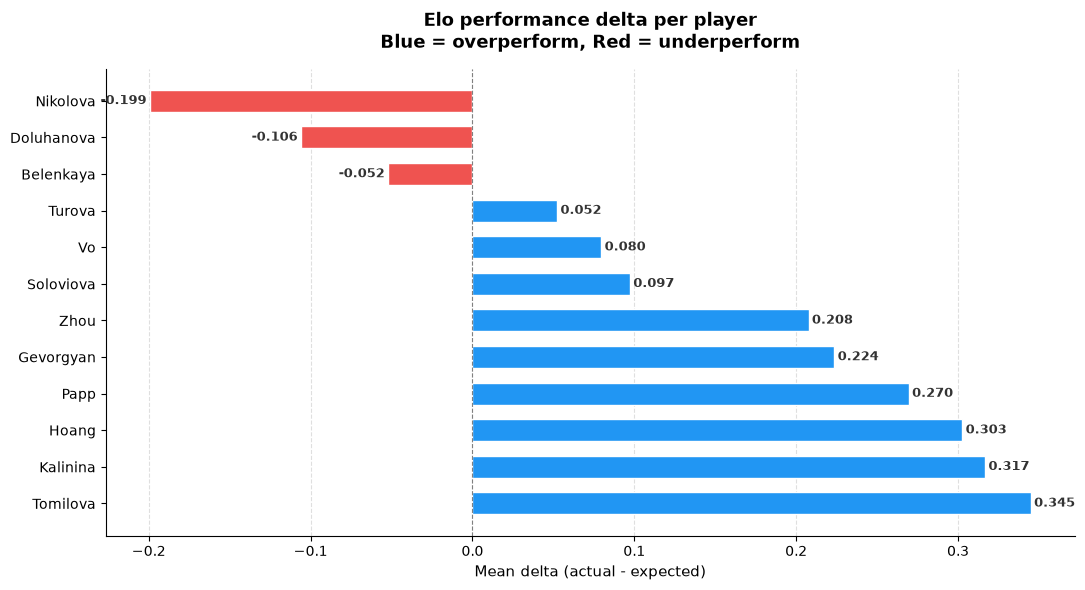

In [19]:
q11_games = games_mapped[
    games_mapped["whiteID"].notna() |
    games_mapped["blackID"].notna()
].copy()

# Prepare FIDE ratings
fide_std = (
    fide[fide["ID"].astype("int64", errors="ignore")
         .isin(mapped_ids)]
    [["ID", "DATE", "SRTNG"]]
    .dropna(subset=["SRTNG"])
    .sort_values(["ID", "DATE"])
).copy()
fide_std["ID"] = fide_std["ID"].astype("int64")

# Merge ratings for white players strictly before game date
white_ratings = q11_games[["game_id", "game_date", "whiteID"]].dropna()
white_ratings["whiteID"] = white_ratings["whiteID"].astype("int64")
white_ratings = white_ratings.merge(
    fide_std.rename(columns={"ID": "whiteID",
                              "DATE": "fide_date",
                              "SRTNG": "white_fide"}),
    on="whiteID", how="left"
)
white_ratings = white_ratings[
    white_ratings["fide_date"] < white_ratings["game_date"]
]
white_ratings = (
    white_ratings.sort_values("fide_date")
    .drop_duplicates(subset=["game_id"], keep="last")
    [["game_id", "white_fide"]]
)

# Merge ratings for black players strictly before game date
black_ratings = q11_games[["game_id", "game_date", "blackID"]].dropna()
black_ratings["blackID"] = black_ratings["blackID"].astype("int64")
black_ratings = black_ratings.merge(
    fide_std.rename(columns={"ID": "blackID",
                              "DATE": "fide_date",
                              "SRTNG": "black_fide"}),
    on="blackID", how="left"
)
black_ratings = black_ratings[
    black_ratings["fide_date"] < black_ratings["game_date"]
]
black_ratings = (
    black_ratings.sort_values("fide_date")
    .drop_duplicates(subset=["game_id"], keep="last")
    [["game_id", "black_fide"]]
)

# Attach ratings and filter games with both ratings
q11_valid = (
    q11_games
    .merge(white_ratings, on="game_id", how="left")
    .merge(black_ratings, on="game_id", how="left")
    .dropna(subset=["white_fide", "black_fide"])
)
print(f"Games with both FIDE ratings: {len(q11_valid)}")

# Elo expected score for white player
q11_valid["expected"] = 1 / (
    1 + 10 ** (
        (q11_valid["black_fide"] - q11_valid["white_fide"]) / 400
    )
)

# Drop chess variants (bughouse, three-check, king of the hill),
# where Elo expectations for standard chess do not apply.
VARIANT_CODES = {"bughousepartnerlose", "threecheck", "kingofthehill"}
q11_valid = q11_valid[
    ~q11_valid["white_result"].isin(VARIANT_CODES) &
    ~q11_valid["black_result"].isin(VARIANT_CODES)
].copy()

# Map actual result to score. chess.com records the *reason* for the
# result (e.g. "checkmated", "resigned", "timeout"), not just win/loss.
DRAW_CODES = {"agreed", "repetition", "stalemate", "insufficient",
              "50move", "timevsinsufficient"}
result = q11_valid["white_result"].astype("string").str.lower()
q11_valid["actual"] = np.select(
    [result == "win", result.isin(DRAW_CODES)], [1.0, 0.5], default=0.0
)
q11_valid.loc[result.isna(), "actual"] = np.nan

# Compute performance delta per game
q11_valid["delta"] = q11_valid["actual"] - q11_valid["expected"]

# Aggregate mean delta per player
performance = (
    q11_valid.dropna(subset=["delta"])
    .groupby("whiteID")["delta"]
    .agg(mean_delta="mean", n_games="count")
    .reset_index()
    .rename(columns={"whiteID": "ID"})
)
performance["ID"] = performance["ID"].astype("int64")
performance = performance[performance["n_games"] >= 5]

# Attach player names
player_names = (
    fide[fide["ID"].astype("int64", errors="ignore")
         .isin(mapped_ids)]
    .drop_duplicates(subset=["ID"])
    [["ID", "NAME"]]
).copy()
player_names["ID"] = player_names["ID"].astype("int64")

performance = (
    performance.merge(player_names, on="ID", how="left")
    .sort_values("mean_delta", ascending=False)
    [["NAME", "ID", "mean_delta", "n_games"]]
)
print(performance.to_string(index=False))

# Horizontal bar chart of mean delta per player
fig, ax = plt.subplots(figsize=(11, 6))

names = [n.split(",")[0] for n in performance["NAME"]]
deltas = performance["mean_delta"].values
colors = ["#2196F3" if v >= 0 else "#EF5350" for v in deltas]

bars = ax.barh(names, deltas, color=colors,
               edgecolor="white", height=0.6)

# Add value labels
for bar, val in zip(bars, deltas):
    ax.text(
        val + 0.002 if val >= 0 else val - 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.3f}",
        va="center",
        ha="left" if val >= 0 else "right",
        fontsize=9, fontweight="bold", color="#333333"
    )

ax.axvline(0, color="gray", linewidth=0.8, linestyle="--")
ax.set_xlabel("Mean delta (actual - expected)", fontsize=11)
ax.set_title("Elo performance delta per player\n"
             "Blue = overperform, Red = underperform",
             fontsize=13, fontweight="bold", pad=15)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.xaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

#### Findings

After restricting to games where both players have a FIDE Standard rating strictly before the game date, 382 games
remain. All 12 linked players have at least 5 games as White. A positive mean delta means the player scored better
than her FIDE rating predicts.

Nine of the 12 players score above expectation. The largest overperformers are Tomilova, Elena (+0.34 per game over
16 games), Kalinina, Olga (+0.32 over 14) and Hoang, Thi Bao Tram (+0.30 over 38). Three players underperform:
Nikolova, Adriana (−0.20 over 56 games), Doluhanova, Evgeniya (−0.11) and Belenkaya, Dina (−0.05).

Two caveats limit how far this can be read:

- Deltas are computed from White's perspective only. Elo's expected score ignores the first-move advantage, so the
  deltas are biased slightly upward.
- These are mostly fast online games (bullet and blitz), compared against a classical FIDE rating. Differences may
  reflect speed-chess skill rather than "online" performance as such.

With 382 games across 12 players, the results are indicative only.

### 12. Hypothesis test — do younger players play more online?

**H3:** *Players below the median age play significantly more online games than older players.*

Tested with a one-sided two-sample *t*-test.


#### Approach

1. Select age and total games per player from the 
   analysis table produced in section 10 — this produces 
   one row per player with age and games.

2. Project median age across all 12 players to define 
   the age threshold.

3. Select two groups:
   younger group: players where age < median age
   older group: players where age >= median age

4. Aggregate mean games per group to compare activity.

5. Apply one-sided t-test:
   H0: mean games is equal between groups
   H1: younger players play more games than older players

6. Plot a boxplot to compare game distributions 
   between the two groups.


Median age: 30.0
Younger group: n=6, mean=8469.7 games
Older group:   n=6, mean=4561.3 games

T-statistic: 0.813
P-value (one-sided): 0.2175


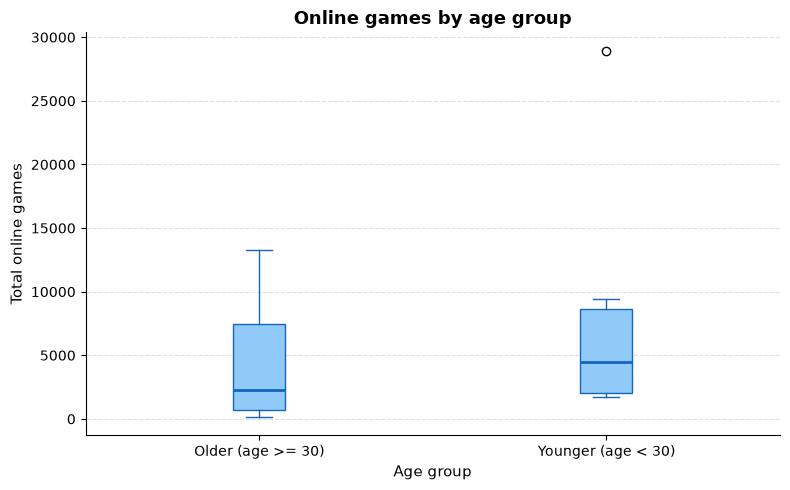

In [20]:
# Split players by median age
median_age = analysis["age"].median()
print(f"Median age: {median_age}")

younger = analysis[analysis["age"] <  median_age]["games"]
older   = analysis[analysis["age"] >= median_age]["games"]

print(f"Younger group: n={len(younger)}, "
      f"mean={younger.mean():.1f} games")
print(f"Older group:   n={len(older)}, "
      f"mean={older.mean():.1f} games")

# H0: mean games equal between groups
# H1: younger players play more games than older players
t_stat, p_value = stats.ttest_ind(
    younger, older, alternative="greater"
)
print(f"\nT-statistic: {t_stat:.3f}")
print(f"P-value (one-sided): {p_value:.4f}")

# Add group label
analysis["group"] = np.where(
    analysis["age"] < median_age,
    f"Younger (age < {int(median_age)})",
    f"Older (age >= {int(median_age)})"
)

# Boxplot
fig, ax = plt.subplots(figsize=(8, 5))
groups = analysis.groupby("group")["games"].apply(list)
ax.boxplot(
    [groups[k] for k in sorted(groups.index)],
    tick_labels=sorted(groups.index),
    patch_artist=True,
    boxprops=dict(facecolor="#90CAF9", color="#1565C0"),
    medianprops=dict(color="#1565C0", linewidth=2),
    whiskerprops=dict(color="#1565C0"),
    capprops=dict(color="#1565C0")
)
ax.set_xlabel("Age group", fontsize=11)
ax.set_ylabel("Total online games", fontsize=11)
ax.set_title("Online games by age group",
             fontsize=13, fontweight="bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.yaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

#### Findings

To test H3, players were split at the median age of 30 years 
into two groups. The younger group (age < 30, n=6) played 
an average of 8,469.7 games, while the older group 
(age >= 30, n=6) played an average of 4,561.3 games.

A one-sided t-test gave t=0.813 and p=0.2175. Since 
p > 0.05 the result is not statistically significant and 
H3 is not supported by the data. Although younger players 
do play more games on average, the difference is not 
large enough to be considered significant.

The main reason for this is the very small sample of only 
12 players. With such a small group it is very hard to 
detect a statistically significant difference even if one 
exists. A larger mapping dataset would be needed to test 
H3 more reliably.


## Conclusion

This project looked at how female chess players perform, 
which countries represent them, and how they play online.

The data showed that most female players get their first 
master title as teenagers, with a median age of 17. The 
results from section 4 supported H1, meaning younger WGMs 
do tend to improve faster after getting their title than 
older ones.

For federations, Russia and India have the most female 
players and are also growing the fastest. Singapore stood 
out as a talent magnet by attracting more players than it 
loses. However H2 was not supported, so having more titles 
per year does not clearly relate to having younger 
recipients.

Part 3 was harder to analyse because only 12 players 
were matched between FIDE and chess.com. This is a 
limitation of the mapping dataset and not of the analysis 
method. From what was available, 9 of the 12 players scored 
above their Elo expectation as White, though first-move 
advantage and time control limit this comparison. H3 was 
also not supported, but with only 12 players the sample 
is too small to detect a significant difference even if 
one exists. A larger mapping dataset would be needed to 
test these hypotheses more reliably.

Overall the analysis gives a useful picture of female 
chess globally, but a bigger mapping dataset would be 
needed to say anything more definitive about online 
playing habits.
